# A Gaussian during training: the Bayesian learning rule

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/argminax/blob/main/docs/notebooks/blr_walkthrough.ipynb)

The transforms of `argminax.blr` are optax optimisers that keep a Gaussian over the parameters in their state. This notebook fits a line to noisy data three ways and compares each with the exact posterior, which a linear model has in closed form:

1. [`blr_diagonal`](xref:api#argminax.blr.blr_diagonal) as a drop-in for `optax.adam`, on minibatches;
2. [`blr_full_rank`](xref:api#argminax.blr.blr_full_rank) with the exact curvature;
3. [`blr_posterior`](xref:api#argminax.blr.blr_posterior), which reads either state as the `Laplace` object the rest of argminax uses.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "argminax[optax] @ git+https://github.com/jejjohnson/argminax@main",
        ],
        check=True,
    )

In [2]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,optax,gaussx,argminax")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax     : 0.12.0.1
optax   : 0.2.9
gaussx  : 0.6.13
argminax: 0.0.6

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



In [3]:
import warnings


# the IProgress and tqdm notices from ipywidgets say nothing about the maths
warnings.filterwarnings("ignore", message=r".*IProgress.*")
warnings.filterwarnings("ignore", category=UserWarning, module=r"tqdm.*")

import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import optax

from argminax.blr import blr_diagonal, blr_full_rank, blr_posterior
from argminax.curvature import marginal_variance
from argminax.diagnose import averaging_kernel, degrees_of_freedom


jax.config.update("jax_enable_x64", True)

## The problem

Two hundred observations $y_n = \theta_1 x_n + \theta_2 + \varepsilon_n$ of a line with slope 2 and intercept $-1$, with noise $\varepsilon_n \sim \mathcal{N}(0, \sigma^2)$, $\sigma = 0.5$, and a prior $\mathcal{N}(\mathbf{0}, \delta^{-1} \mathbf{I})$ with $\delta = 1$ on the two parameters $\boldsymbol{\theta} = (\theta_1, \theta_2)$.

With the features $\boldsymbol{\Phi}$ of shape $(200, 2)$ (a column of $x_n$ and a column of ones), the cost is $\mathcal{J}(\boldsymbol{\theta}) = \lVert \mathbf{y} - \boldsymbol{\Phi} \boldsymbol{\theta} \rVert^2 / (2 \sigma^2)$, its curvature is $\mathbf{C} = \boldsymbol{\Phi}^\top \boldsymbol{\Phi} / \sigma^2$, and the posterior is exactly Gaussian, with precision $\delta \mathbf{I} + \mathbf{C}$.

In [4]:
NUM_OBS, NOISE_STD, PRIOR_PRECISION = 200, 0.5, 1.0

key_inputs, key_noise = jax.random.split(jax.random.key(0))
inputs = jax.random.uniform(key_inputs, (NUM_OBS,), minval=-2.0, maxval=2.0)
noise = NOISE_STD * jax.random.normal(key_noise, (NUM_OBS,))
targets = 2.0 * inputs - 1.0 + noise
features = jnp.column_stack([inputs, jnp.ones(NUM_OBS)])  # (200, 2)

# C = ΦᵀΦ / σ²
curvature = features.T @ features / NOISE_STD**2
# Λ = δ I + C,  μ = Λ⁻¹ Φᵀy / σ²
exact_precision = PRIOR_PRECISION * jnp.eye(2) + curvature
exact_mean = jnp.linalg.solve(exact_precision, features.T @ targets / NOISE_STD**2)
exact_covariance = jnp.linalg.inv(exact_precision)
exact_std = jnp.sqrt(jnp.diag(exact_covariance))

print("exact posterior mean:", exact_mean)
print("exact posterior std: ", exact_std)

exact posterior mean: [ 2.01638029 -0.98867046]
exact posterior std:  [0.03055663 0.03542043]


## 1. A drop-in for Adam

`blr_diagonal` takes the gradient of a minibatch cost, exactly as `optax.adam` does. Here the cost is the mean over the minibatch. Its default curvature estimate is the squared gradient (`"ggn"`), which needs nothing but the gradient.

In [5]:
def minibatch_cost(theta, batch):
    # the mean over the minibatch of (yₙ − θ₁xₙ − θ₂)² / (2σ²)
    misfit = targets[batch] - features[batch] @ theta
    return 0.5 * jnp.mean(misfit**2) / NOISE_STD**2


diagonal = blr_diagonal(0.05, prior_precision=1e-2)
batches = jax.random.permutation(jax.random.key(1), NUM_OBS).reshape(10, 20)


def diagonal_step(carry, batch):
    theta, state = carry
    grads = jax.grad(minibatch_cost)(theta, batch)
    updates, state = diagonal.update(grads, state)
    theta = optax.apply_updates(theta, updates)
    return (theta, state), (theta, 1.0 / jnp.sqrt(state.precision))


theta = jnp.zeros(2)
epochs = jnp.tile(batches, (100, 1))  # 1000 steps
(theta, diagonal_state), (diagonal_means, diagonal_stds) = jax.lax.scan(
    diagonal_step, (theta, diagonal.init(theta)), epochs
)

diagonal_posterior = blr_posterior(diagonal_state)
print("mean:", diagonal_posterior.mode)
print("std: ", jnp.sqrt(marginal_variance(diagonal_posterior)))

mean: [ 2.07339692 -0.83293843]
std:  [1.43134459 2.31507391]


The mean finds the line, with the scatter of minibatch training. The standard deviation does not: the squared gradient is not the curvature, and it shrinks to zero where the gradient does, so the precision falls back towards the prior. Read `"ggn"` as an adaptive step size, not as a posterior width.

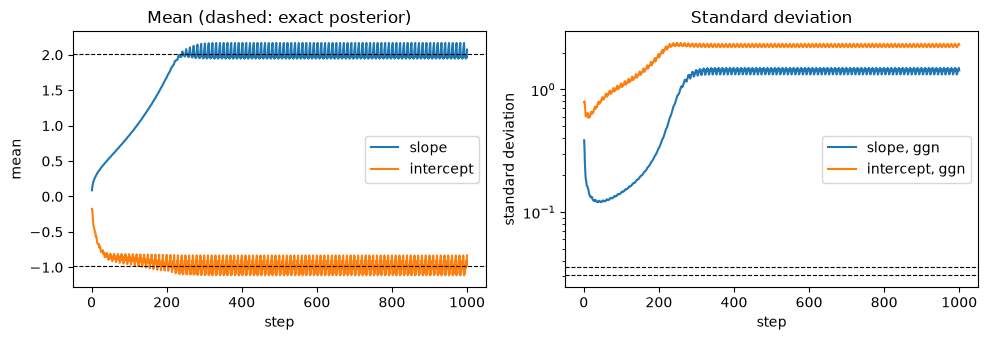

In [6]:
steps = jnp.arange(1, diagonal_means.shape[0] + 1)
names = ["slope", "intercept"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for index, name in enumerate(names):
    axes[0].plot(steps, diagonal_means[:, index], label=name)
    axes[0].axhline(exact_mean[index], color="k", linestyle="--", linewidth=0.8)
    axes[1].semilogy(steps, diagonal_stds[:, index], label=f"{name}, ggn")
    axes[1].axhline(exact_std[index], color="k", linestyle="--", linewidth=0.8)
axes[0].set(xlabel="step", ylabel="mean", title="Mean (dashed: exact posterior)")
axes[1].set(xlabel="step", ylabel="standard deviation", title="Standard deviation")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
plt.show()

## 2. The exact curvature

`blr_full_rank` keeps a dense precision and accepts the curvature as a callable. With the exact $\mathbf{C}$ the rule's fixed point is the exact posterior, and each step closes a fraction $\alpha$ of the gap in the natural parameters. With $\alpha = 1$ it would arrive in one step; $\alpha = 0.2$ shows the approach.

In [7]:
def cost(theta):
    # 𝒥(θ) = ‖y − Φθ‖² / (2σ²)
    return 0.5 * jnp.sum((targets - features @ theta) ** 2) / NOISE_STD**2


full_rank = blr_full_rank(
    0.2,
    prior_precision=PRIOR_PRECISION,
    curvature=lambda mean, grad: curvature,
    damping=0.0,
)


def full_rank_step(carry, _):
    theta, state = carry
    updates, state = full_rank.update(jax.grad(cost)(theta), state)
    theta = theta + updates
    covariance = jnp.linalg.inv(state.precision)
    return (theta, state), (theta, jnp.sqrt(jnp.diag(covariance)))


theta = jnp.zeros(2)
(theta, full_rank_state), (full_means, full_stds) = jax.lax.scan(
    full_rank_step, (theta, full_rank.init(theta)), length=40
)

posterior = blr_posterior(full_rank_state)
print("mean:", posterior.mode, " exact:", exact_mean)
print("std: ", jnp.sqrt(marginal_variance(posterior)), " exact:", exact_std)

mean: [ 2.01638003 -0.98867028]  exact: [ 2.01638029 -0.98867046]
std:  [0.03055866 0.03542278]  exact: [0.03055663 0.03542043]


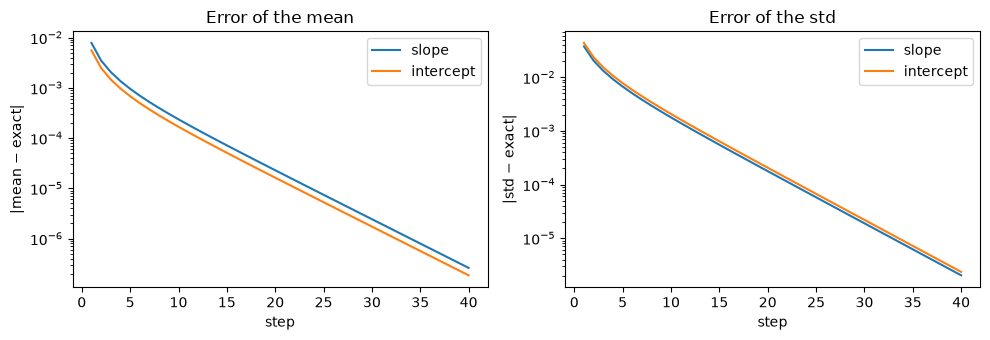

In [8]:
steps = jnp.arange(1, 41)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for index, name in enumerate(names):
    mean_error = jnp.abs(full_means[:, index] - exact_mean[index])
    std_error = jnp.abs(full_stds[:, index] - exact_std[index])
    axes[0].semilogy(steps, mean_error, label=name)
    axes[1].semilogy(steps, std_error, label=name)
axes[0].set(xlabel="step", ylabel="|mean − exact|", title="Error of the mean")
axes[1].set(xlabel="step", ylabel="|std − exact|", title="Error of the std")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
plt.show()

## 3. The state as a posterior

`blr_posterior` returned a `Laplace` in both cases, so everything argminax does with a posterior works on an optimiser state: draws, marginal variances, and the retrieval diagnostics. Here are 500 draws against the two-standard-deviation ellipse of the exact posterior, and the degrees of freedom for signal, which count how many of the two parameters the data determined.

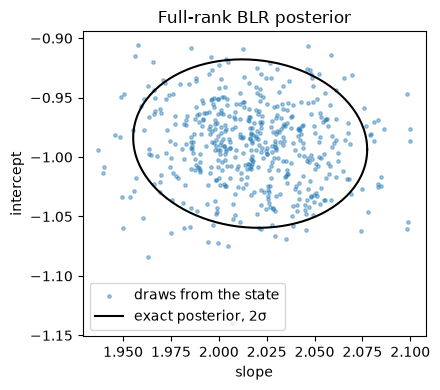

degrees of freedom for signal: 1.998 of 2


In [9]:
draws = posterior.sample(500, key=jax.random.key(2))  # (500, 2)

# the 2σ ellipse of the exact posterior: μ + 2 L (cos t, sin t), Σ = L Lᵀ
angles = jnp.linspace(0.0, 2.0 * jnp.pi, 200)
circle = jnp.column_stack([jnp.cos(angles), jnp.sin(angles)])  # (200, 2)
ellipse = exact_mean + 2.0 * circle @ jnp.linalg.cholesky(exact_covariance).T

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(draws[:, 0], draws[:, 1], s=6, alpha=0.4, label="draws from the state")
ax.plot(ellipse[:, 0], ellipse[:, 1], color="k", label="exact posterior, 2σ")
ax.set(xlabel="slope", ylabel="intercept", title="Full-rank BLR posterior")
ax.legend()
fig.tight_layout()
plt.show()

prior_cov = lx.MatrixLinearOperator(
    jnp.eye(2) / PRIOR_PRECISION, lx.positive_semidefinite_tag
)
dofs = degrees_of_freedom(averaging_kernel(posterior, prior_cov)).value
print(f"degrees of freedom for signal: {dofs:.3f} of 2")

## Composing with optax

A transform chains like any other. The state of the chain is a tuple, and the BLR state is the link it was placed at.

In [10]:
chained = optax.chain(optax.clip_by_global_norm(1.0), blr_diagonal(0.05))
theta = jnp.zeros(2)
state = chained.init(theta)
for batch in batches:
    grads = jax.grad(minibatch_cost)(theta, batch)
    updates, state = chained.update(grads, state)
    theta = optax.apply_updates(theta, updates)

print("mean after one clipped epoch:", blr_posterior(state[1]).mode)

mean after one clipped epoch: [ 2.18386099 -0.775291  ]


## Summary

- `blr_diagonal` is a drop-in for `optax.adam` on any parameter pytree. Its default squared-gradient curvature makes a good adaptive optimiser and a poor posterior width.
- `blr_full_rank` with the exact curvature converges to the exact posterior of a quadratic cost, and to the Laplace approximation otherwise.
- `blr_posterior` turns either state into a `Laplace`, so sampling and the diagnostics of `argminax.diagnose` apply to it unchanged.

The [guide](../guide/blr.md) derives the rule and lists what each transform stores and costs.